In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline

# Encontrar a pasta ML
candidatos = [
    Path.cwd(),
    Path.cwd() / "ML",
    Path.cwd().parent,
]

BASE = next(
    (
        pasta for pasta in candidatos
        if (pasta / "dados/modelagem/treino_2022_2024.csv").exists()
    ),
    None,
)

if BASE is None:
    raise FileNotFoundError("Pasta de dados do AlertaSP não encontrada.")

DADOS = BASE / "dados/modelagem"
RESULTADOS = BASE / "resultados"
RESULTADOS.mkdir(exist_ok=True)

ALVO = "alvo_registro_amanha"

treino = pd.read_csv(
    DADOS / "treino_2022_2024.csv",
    parse_dates=["data"],
).sort_values("data")

validacao = pd.read_csv(
    DADOS / "validacao_2025.csv",
    parse_dates=["data"],
).sort_values("data")

FEATURES = [
    coluna for coluna in treino.columns
    if coluna not in ("data", ALVO)
]

X_treino = treino[FEATURES]
y_treino = treino[ALVO].astype(int)

X_validacao = validacao[FEATURES]
y_validacao = validacao[ALVO].astype(int)

assert len(FEATURES) == 12
assert treino["data"].max() < validacao["data"].min()

print("Treinamento:", len(treino))
print("Validação:", len(validacao))
print("Features:", len(FEATURES))

display(treino.head())

Treinamento: 1093
Validação: 364
Features: 12


,data,chuva_mm_a701,temperatura_media_c_a701,umidade_media_pct_a701,chuva_acumulada_3d_a701,chuva_acumulada_7d_a701,chuva_mm_a771,temperatura_media_c_a771,umidade_media_pct_a771,chuva_acumulada_3d_a771,chuva_acumulada_7d_a771,dia_ano_seno,dia_ano_cosseno,alvo_registro_amanha
0,2022-01-01,3.6,21.083333,81.875000,NaN,NaN,0.6,21.450000,88.500000,NaN,NaN,0.017202,0.999852,1
1,2022-01-02,2.8,22.875000,76.583333,NaN,NaN,0.0,23.141667,82.666667,NaN,NaN,0.034398,0.999408,1
2,2022-01-03,19.8,22.537500,82.083333,26.2,NaN,1.0,22.970833,85.625000,1.6,NaN,0.051584,0.998669,1
3,2022-01-04,15.0,22.570833,81.875000,37.6,NaN,13.2,22.362500,93.333333,14.2,NaN,0.068755,0.997634,1
4,2022-01-05,4.8,22.904167,76.541667,39.6,NaN,12.0,23.233333,87.208333,26.2,NaN,0.085906,0.996303,1


In [2]:
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    (
        "modelo",
        RandomForestClassifier(
            random_state=42,
            class_weight="balanced_subsample",
            n_jobs=1,
        ),
    ),
])

parametros = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__max_depth": [5, 10],
    "modelo__min_samples_leaf": [2, 5],
}

busca = GridSearchCV(
    estimator=pipeline,
    param_grid=parametros,
    scoring="average_precision",
    cv=TimeSeriesSplit(n_splits=4, gap=1),
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)

busca.fit(X_treino, y_treino)

modelo = busca.best_estimator_

print("Melhores parâmetros:")
print(busca.best_params_)

print("\nAverage Precision média da validação cruzada:")
print(round(busca.best_score_, 4))

resultados_cv = pd.DataFrame(busca.cv_results_)

display(
    resultados_cv[
        [
            "params",
            "mean_train_score",
            "mean_test_score",
            "rank_test_score",
        ]
    ].sort_values("rank_test_score")
)

Melhores parâmetros:
{'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}

Average Precision média da validação cruzada:
0.6463


,params,mean_train_score,mean_test_score,rank_test_score
5,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.896595,0.646310,1
3,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.895049,0.645270,2
9,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.946131,0.645179,3
11,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.948518,0.644081,4
4,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.895709,0.643250,5
10,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.947882,0.642281,6
2,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.920000,0.642132,7
1,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.920317,0.637749,8
0,"{'modelo__max_depth': 5, 'modelo__min_samples_...",0.918098,0.637145,9
6,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.995175,0.620708,10


In [3]:
def avaliar(nome, X, y):
    probabilidades = modelo.predict_proba(X)[:, 1]
    previsoes = (probabilidades >= 0.5).astype(int)

    return {
        "Conjunto": nome,
        "Accuracy": accuracy_score(y, previsoes),
        "Precision": precision_score(y, previsoes, zero_division=0),
        "Recall": recall_score(y, previsoes, zero_division=0),
        "F1": f1_score(y, previsoes, zero_division=0),
        "Average Precision": average_precision_score(y, probabilidades),
        "ROC-AUC": roc_auc_score(y, probabilidades),
    }


metricas = pd.DataFrame([
    avaliar("Treinamento", X_treino, y_treino),
    avaliar("Validação 2025", X_validacao, y_validacao),
])

display(metricas.round(4))

print("Referência AP 2025:", round(y_validacao.mean(), 4))

metricas.to_csv(
    RESULTADOS / "10_metricas_notebook.csv",
    index=False,
)

,Conjunto,Accuracy,Precision,Recall,F1,Average Precision,ROC-AUC
0,Treinamento,0.8161,0.6427,0.8549,0.7338,0.8341,0.9132
1,Validação 2025,0.7527,0.4803,0.7176,0.5755,0.6237,0.8315


Referência AP 2025: 0.2335


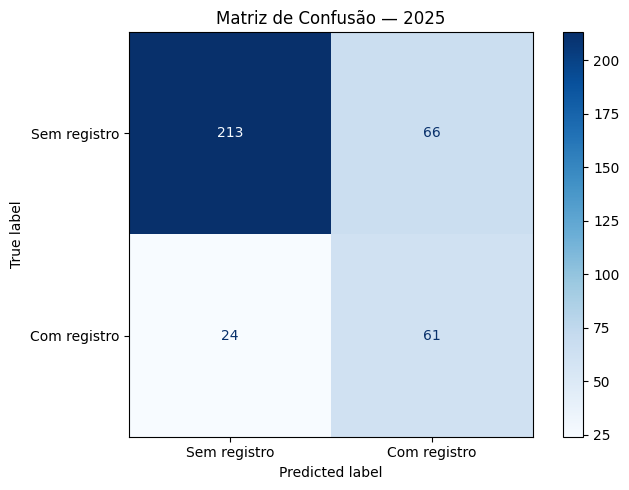

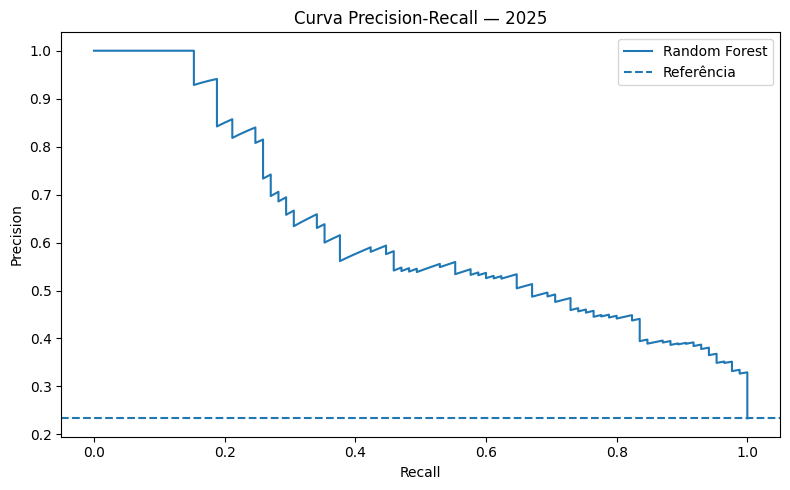

In [4]:
probabilidades = modelo.predict_proba(X_validacao)[:, 1]
previsoes = (probabilidades >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_validacao,
    previsoes,
    labels=[0, 1],
    display_labels=["Sem registro", "Com registro"],
    cmap="Blues",
    ax=ax,
)

ax.set_title("Matriz de Confusão — 2025")
plt.tight_layout()
plt.show()


precision, recall, _ = precision_recall_curve(
    y_validacao,
    probabilidades,
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(recall, precision, label="Random Forest")
ax.axhline(
    y_validacao.mean(),
    linestyle="--",
    label="Referência",
)

ax.set_title("Curva Precision-Recall — 2025")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()

plt.tight_layout()
plt.show()